# Notebook 08: Advanced Analysis of the Real and the Synthetic Data
**Project:** Real vs. Synthetic Data: Comparative Analysis and Visualization

The brief asks for at least three advanced tasks in Python, with checked assumptions, test statistics, p-values and a distinction between statistical significance and practical importance. This notebook performs four:

1. **Hypothesis testing**: Welch t-test and Mann-Whitney U test for the 14 numerical columns and the chi-square test for the 10 categorical columns, real against synthetic, with Holm correction and effect sizes.
2. **PCA**: two-dimensional projection of real and synthetic points, similarity of the components, and a classifier two-sample test (can a model tell the two datasets apart?).
3. **Feature importance**: which attributes predict a purchase (`Revenue`), with a model trained on the real data, on the synthetic data and on both, always tested on held-out real data.
4. **Clustering**: K-Means on both datasets and a comparison of the cluster structure.

**Design choices.** (a) The real and the synthetic samples are *not* independent: the synthetic rows were generated from the real ones. The tests below therefore answer "is the difference between the two datasets detectable and how large is it?", not a question about two independent populations. (b) PCA, clustering and prediction use the ten base numerical columns (and seven base categorical columns for prediction); the four derived columns and the two derived categorical columns (Quarter, Session_Length_Band) are left out, because they are exact functions of the others. (c) Seed 42 everywhere, scikit-learn defaults otherwise. The Combined dataset is not analysed separately here, because the brief asks for this task on the real and the synthetic data; a test of real against Combined would compare the real data with a 50/50 mixture of itself and the synthetic data and would only dilute every difference. Task 3 does use real plus synthetic rows as one of its training sets.

## 1. Setup

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn, scipy
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import scenario_lib as L
import advanced_lib as A
L.use_style()

real = pd.read_csv(ROOT / "data" / "cleaned" / "online_shoppers_cleaned.csv")
syn = pd.read_csv(ROOT / "data" / "synthetic" / "synthetic_online_shoppers.csv")
FIG = ROOT / "figures" / "advanced"; RES = ROOT / "results" / "advanced"
for p in (FIG, RES): p.mkdir(parents=True, exist_ok=True)
import matplotlib, sdv
print(real.shape, syn.shape, "| pandas", pd.__version__, "| numpy", np.__version__, "| scipy", scipy.__version__, "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__, "| sdv", sdv.__version__)

(12199, 24) (12199, 24) | pandas 2.3.3 | numpy 2.5.3 | scipy 1.18.1 | scikit-learn 1.9.1 | matplotlib 3.11.2 | sdv 2.2.0


## 2. Task 1: Hypothesis tests (real vs. synthetic)
### 2.1 Assumptions
The t-test assumes approximately normal data (or large samples) and, for the standard version, equal variances; the Mann-Whitney test assumes only independent observations from continuous or ordinal data and tests whether values of one dataset tend to be larger than those of the other (it works on ranks; it is not a test of equality of the whole distributions). Normality is checked with the Shapiro-Wilk test on a seeded sample of 5,000 rows (the test becomes oversensitive for very large samples), skewness is reported next to it, and equal variances are checked with Levene's test (median-centred).

In [2]:
assump = A.assumption_table(real, syn); assump.to_csv(RES / "test_assumptions.csv")
assump.round(4)

,skew real,skew synthetic,Shapiro p real,Shapiro p synthetic,Levene p,std ratio
column,,,,,,
Administrative,1.9462,1.6563,0.0,0.0,0.0000,0.7809
Administrative_Duration,3.8159,4.0214,0.0,0.0,0.0000,0.6821
Informational,4.0126,1.2252,0.0,0.0,0.0000,0.7891
Informational_Duration,5.5401,2.9013,0.0,0.0,0.0000,0.3969
ProductRelated,3.0557,3.1019,0.0,0.0,0.0008,1.1312
ProductRelated_Duration,3.0215,3.1165,0.0,0.0,0.0002,1.2000
BounceRates,3.1733,3.5705,0.0,0.0,0.0000,0.5534
ExitRates,2.2386,2.1194,0.0,0.0,0.0334,0.9009
PageValues,6.3487,2.3688,0.0,0.0,0.2843,0.5472


**Interpretation.** No column is normal: the Shapiro-Wilk p-value is below 0.001 for all 14 columns in both datasets, and the skewness is large (from 1.2 to 10.3 in absolute value; Product_Page_Share is skewed to the left). The variances also differ: Levene's test rejects equal variances for 11 of 14 columns (not for PageValues, SpecialDay and, borderline, Total_Duration), and the ratio of the synthetic to the real standard deviation lies between 0.40 (Informational_Duration) and 1.20 (ProductRelated_Duration). The assumptions of the standard t-test are therefore not met. With 12,199 rows per group, the Welch version still gives a valid test of the *means* (central limit theorem), but means summarise these zero-heavy, skewed columns poorly, so the Mann-Whitney test, which works on ranks and asks whether values of one dataset tend to be larger than those of the other, is used as the primary test (it is not a test of equality of the whole distributions).

### 2.2 Numerical columns: Welch t-test and Mann-Whitney U test
The Welch t-test (unequal variances) is shown for completeness; the Mann-Whitney test is the primary test because no column is normal. P-values are adjusted for 14 tests with the Holm method. Effect sizes: Cohen's d = (real mean - synthetic mean) / pooled standard deviation, and the rank-biserial correlation = P(real > synthetic) - P(real < synthetic), so a negative value means that real values tend to be smaller (values below 0.2 and 0.1 are treated as negligible; Cohen's thresholds are conventions, not laws). A difference is called *non-negligible* here if |d| ≥ 0.2 or |rank-biserial| ≥ 0.1 (for categorical columns: Cramér's V ≥ 0.1); this is a convention, and a rank-biserial value of 0.1 corresponds to a small effect.

In [3]:
nt = A.numeric_tests(real, syn); nt.to_csv(RES / "numeric_tests.csv")
nt[["Welch t", "Welch p", "Welch p (Holm)", "Cohen d", "U", "MWU p", "MWU p (Holm)", "rank-biserial", "significant (Holm, 5%)", "non-negligible", "KS"]]

,Welch t,Welch p,Welch p (Holm),Cohen d,U,MWU p,MWU p (Holm),rank-biserial,"significant (Holm, 5%)",non-negligible,KS
column,,,,,,,,,,,
Administrative,4.809679,1.521278e-06,1.217023e-05,0.061584,72667920.5,8.950075e-04,8.055067e-03,-0.023383,True,False,0.090253
Administrative_Duration,10.550676,5.835876e-26,6.419463e-25,0.135093,75460392.0,4.281384e-02,3.425108e-01,0.014146,False,False,0.045823
Informational,-9.136206,6.985011e-20,6.985011e-19,-0.116982,66399142.5,6.056110e-78,8.478554e-77,-0.107632,True,True,0.126978
Informational_Duration,8.973330,3.191488e-19,2.872339e-18,0.114896,70045986.0,3.139703e-27,3.453673e-26,-0.058620,True,False,0.094188
ProductRelated,-2.448228,1.436319e-02,7.181594e-02,-0.031348,75281980.5,1.119157e-01,7.834102e-01,0.011748,False,False,0.030740
ProductRelated_Duration,-3.321721,8.959962e-04,6.271974e-03,-0.042532,75028209.0,2.593617e-01,1.000000e+00,0.008338,False,False,0.044512
BounceRates,13.812351,3.469831e-43,4.857764e-42,0.176856,73587436.0,1.178673e-01,7.834102e-01,-0.011025,False,False,0.047217
ExitRates,2.557546,1.054741e-02,6.328448e-02,0.032747,74672234.0,6.307038e-01,1.000000e+00,0.003554,False,False,0.031396
PageValues,1.070736,2.843018e-01,5.686036e-01,0.013710,66871942.5,1.017139e-67,1.322280e-66,-0.101278,True,True,0.136405


**Interpretation.** The two tests disagree, and the disagreement is informative. The Welch t-test finds a difference in the means for 12 of 14 columns (8 after the Holm correction), the Mann-Whitney test finds a difference in the ranking of the values for 6 columns after the correction: Administrative, Informational, Informational_Duration, PageValues, Avg_Time_Per_Page and Product_Page_Share. PageValues shows the pattern most clearly: the means are almost equal (Welch p = 0.28, d = 0.01), but the values are ranked differently (Mann-Whitney p < 0.001, rank-biserial -0.10), because the synthetic data has fewer zeros (67.1% against 77.6%) and fewer extreme values. BounceRates is the opposite: the means differ (Welch p < 0.001, d = 0.18) but the typical values do not (Mann-Whitney p = 0.12, rank-biserial -0.01), because the difference sits in the tail of the distribution. **Statistical significance against practical importance:** the effects are small. No column reaches |d| = 0.2 (largest 0.18, BounceRates); the largest absolute rank-biserial values are 0.11 (Product_Page_Share), 0.11 (Informational) and 0.10 (PageValues), which are just above the 0.1 threshold used here, so these three are classed as non-negligible (still small effects) and the other three significant columns (for example Administrative, rank-biserial -0.02, Holm p = 0.008) as significant but negligible. A negative rank-biserial value means that real values tend to be smaller than synthetic ones (PageValues, Informational), a positive one that they tend to be larger (Product_Page_Share). Large samples make very small differences detectable; the effect size, not the p-value, says how much the two datasets differ.

### 2.3 Categorical columns: chi-square test
Chi-square test of homogeneity (is the distribution of the column the same in both datasets?), without continuity correction, Cramér's V as effect size (below 0.1 is negligible) and Holm-adjusted p-values over 10 tests. The chi-square approximation needs expected counts of at least 5; where that fails (see `min expected count`), the test is repeated after pooling levels with fewer than 50 rows.

In [4]:
ct = A.categorical_tests(real, syn); ct.to_csv(RES / "categorical_tests.csv")
ct.round(4)

,levels,chi2,dof,p,p (rare levels pooled),Cramer's V,min expected count,p (Holm),"significant (Holm, 5%)",non-negligible
column,,,,,,,,,,
Month,10,7.4636,9,0.5890,0.5890,0.0175,173.5,1.0000,False,False
Quarter,4,3.1064,3,0.3755,0.3755,0.0113,1320.5,1.0000,False,False
VisitorType,3,2.5199,2,0.2837,0.2837,0.0102,78.0,1.0000,False,False
Weekend,2,3.9849,1,0.0459,0.0459,0.0128,2792.5,0.4132,False,False
OperatingSystems,8,7.7570,7,0.3545,0.2592,0.0178,5.5,1.0000,False,False
Browser,13,4.6378,12,0.9690,0.9536,0.0138,1.5,1.0000,False,False
Region,9,11.1002,8,0.1961,0.1961,0.0213,325.5,1.0000,False,False
TrafficType,20,13.5131,19,0.8113,0.6115,0.0235,1.0,1.0000,False,False
Session_Length_Band,3,3.6323,2,0.1627,0.1627,0.0122,3933.5,1.0000,False,False


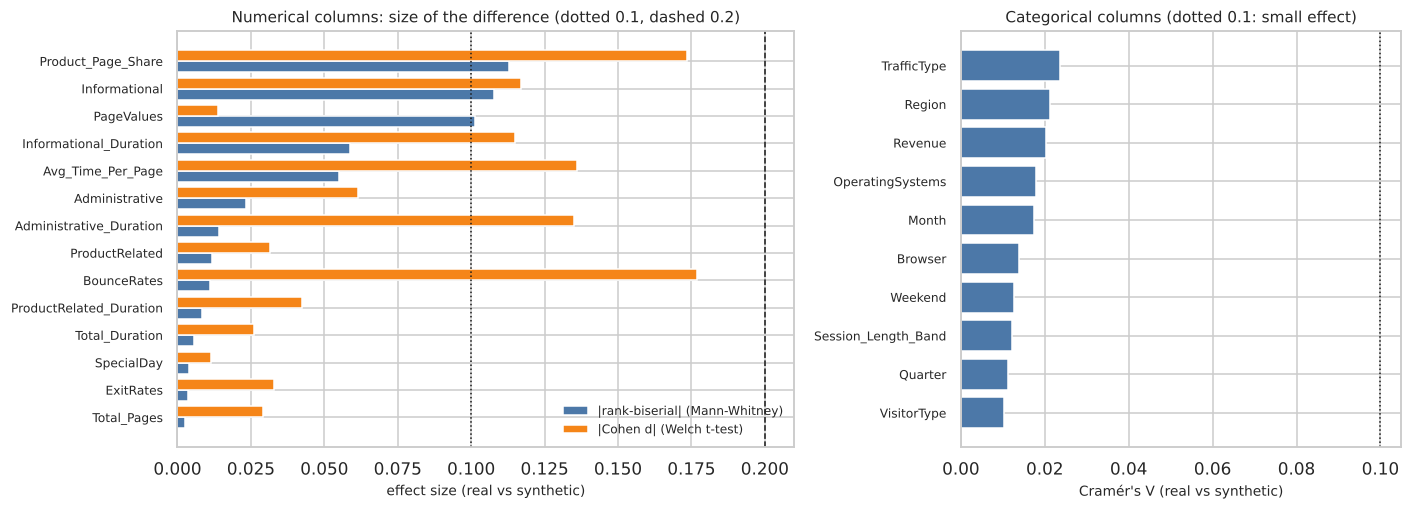

In [5]:
A.fig_tests(nt, ct, FIG / "a01_hypothesis_test_effect_sizes.png")

**Interpretation.** The left panel of the figure repeats the effect sizes of the numerical columns of Section 2.2 (every |d| and |rank-biserial| is below 0.2, and only three bars pass the dotted line at 0.1); the right panel shows Cramér's V for the categorical columns, discussed here. Eight of the ten categorical columns show no significant difference between the real and the synthetic data (unadjusted p from 0.16 to 0.97). Revenue does (chi-square 10.1, p = 0.0015, Holm-adjusted 0.015): 14.2% of the synthetic sessions end in a purchase against 15.6% of the real ones. Weekend is borderline before the correction (p = 0.046) and not significant after it (Holm p = 0.41). All effect sizes are tiny (Cramér's V from 0.010 to 0.024, none close to 0.1), so even the significant Revenue difference is practically small. For Browser and TrafficType the smallest expected counts (1.5 and 1.0) are below the usual minimum of 5; after pooling the rare levels the p-values are 0.95 and 0.61 (and 0.26 for OperatingSystems), so the conclusion does not depend on this. A non-significant result does not prove that the proportions are equal; it only shows that a difference of this size cannot be detected with 12,199 rows. Note also that these tests compare one column at a time and cannot see whether the *combinations* of categories are right, which Phase 6 showed they are not (mean change in Cramér's V between column pairs 0.10).

## 3. Task 2: PCA
The ten base numerical columns are transformed with log(1 + x) (they are right-skewed and have many zeros), standardised with the **real** mean and standard deviation, and projected on the principal components of the **real** data. The synthetic points are projected on the same axes, so that any difference in the picture is a difference in the data. A second PCA fitted on the synthetic data alone is used to compare variance and loadings.

In [6]:
pca = A.pca_analysis(real, syn)
pca["var"].set_index("component").round(3).to_csv(RES / "pca_components.csv")
pca["loadings_real"].round(3).to_csv(RES / "pca_loadings_real.csv"); pca["loadings_syn"].round(3).to_csv(RES / "pca_loadings_synthetic.csv")
display(pca["var"].set_index("component").round(3)); display(pca["loadings_real"].round(2))

,explained variance real,explained variance synthetic (own PCA),loading cosine similarity,KS of scores (synthetic projected on real PCA),mean score real,mean score synthetic,std score real,std score synthetic
component,,,,,,,,
PC1,0.432,0.330,0.989,0.046,0.0,0.234,2.080,1.669
PC2,0.172,0.157,0.914,0.091,-0.0,0.106,1.311,1.183
PC3,0.118,0.130,0.831,0.047,0.0,-0.098,1.086,1.105
PC4,0.097,0.101,0.869,0.058,0.0,-0.066,0.985,1.002
PC5,0.086,0.097,0.650,0.137,0.0,0.184,0.929,0.995


,PC1,PC2,PC3,PC4,PC5
Administrative,0.35,0.20,0.48,0.24,-0.19
Administrative_Duration,0.35,0.17,0.51,0.23,-0.20
Informational,0.28,0.52,-0.33,-0.15,-0.02
Informational_Duration,0.28,0.52,-0.34,-0.15,-0.01
ProductRelated,0.38,-0.11,-0.17,0.12,0.05
ProductRelated_Duration,0.40,-0.25,-0.22,0.03,0.02
BounceRates,-0.33,0.42,0.13,0.14,0.12
ExitRates,-0.38,0.37,0.07,0.10,0.07
PageValues,0.19,0.02,0.19,0.06,0.95
SpecialDay,-0.07,-0.01,-0.39,0.89,0.00


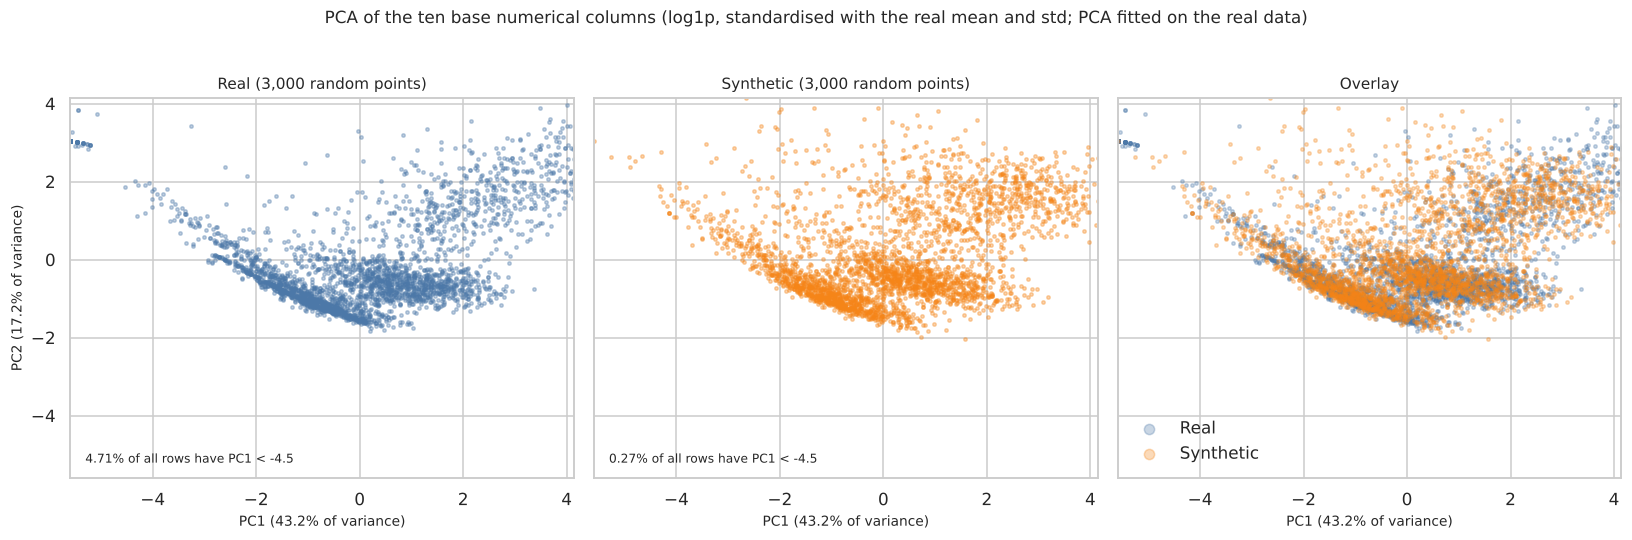

In [7]:
A.fig_pca(pca, FIG / "a02_pca_scatter.png")

**Interpretation.** The first two components explain 60% of the real variance (PC1 43%, PC2 17%), and the real points form the same arched shape in the plane of PC1 (overall activity level) and PC2 (informational pages and bounce behaviour). The synthetic points occupy the same region and have the same overall arch, so the large-scale structure is reproduced. There are two visible differences. First, a dense group at the far left of the real plot is almost absent from the synthetic plot: 4.7% of the real rows have PC1 below -4.5 against 0.27% of the synthetic rows. These are sessions with a bounce and exit rate of about 0.2 and almost no page views; the synthetic data has such sessions much less often (6.4% of the real rows have a bounce rate of at least 0.1, against 1.7% of the synthetic rows). Second, the synthetic scores have a smaller spread on PC1 (standard deviation 1.67 against 2.08) and are shifted slightly to the right (mean 0.23).

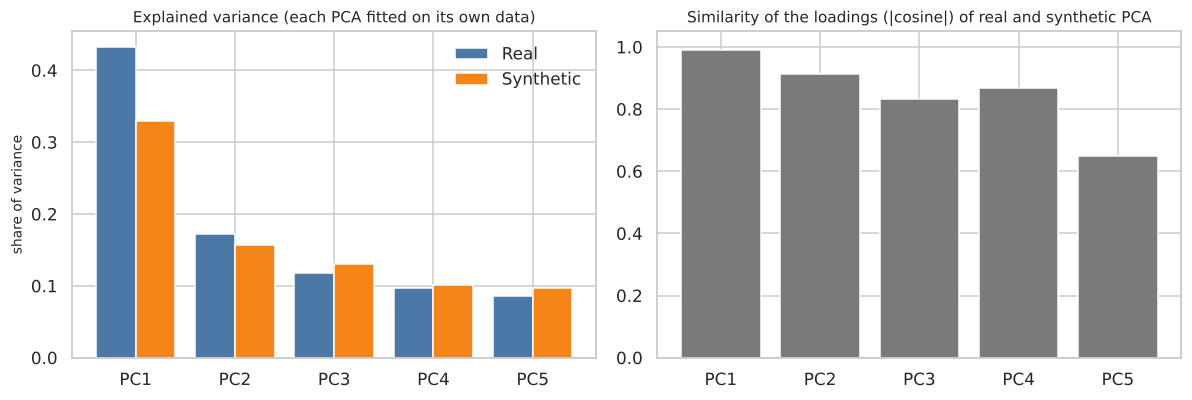

In [8]:
A.fig_pca_variance(pca, FIG / "a03_pca_variance_and_loadings.png")

**Interpretation.** The explained variance shows how strongly the columns move together. In the real data PC1 explains 43.2% of the variance, in the synthetic data 33.0%: the columns are less strongly correlated in the synthetic data, in line with the weakened correlations of Phase 6. The remaining components explain similar shares (PC2 17.2% against 15.7%, PC3 11.8% against 13.0%). The loadings of the first component are almost identical (|cosine| 0.99: both are a general activity axis, with all counts and durations positive and bounce and exit rates negative). The similarity falls for the later components (0.91, 0.83, 0.87 and 0.65 for PC2 to PC5). PC5 is the clearest example: in the real data it is almost purely PageValues (loading 0.95), in the synthetic data it mixes PageValues (0.55), SpecialDay (-0.49) and BounceRates (0.46). The eigenvalues of PC3 to PC5 are close to each other (8.6% to 11.8% of the real variance), so these components can rotate and their loading similarities are less stable than that of PC1; they should be read as a hint, not as a result. Projected on the real axes, the Kolmogorov-Smirnov distances of the scores are 0.05 (PC1), 0.09 (PC2), 0.05, 0.06 and 0.14 (PC5), the largest on the PageValues component.

### 3.1 Classifier two-sample test
A gradient-boosting classifier is trained to separate real from synthetic rows (5-fold cross-validation, all 24 columns, then numerical and categorical columns alone). The ROC AUC is 0.5 if the two datasets are indistinguishable and 1.0 if they are perfectly separable. The last row is a control: every column is shuffled independently within each dataset, which keeps each column's distribution but destroys all relationships between columns. The AUC that remains shows how much the column distributions alone give away; the rest comes from the joint structure.

In [9]:
clf2 = A.two_sample_classifier(real, syn)
clf2["all columns, every column shuffled independently (relationships destroyed)"] = A.shuffled_marginals_auc(real, syn)
clf2.round(3).to_csv(RES / "classifier_two_sample_auc.csv")
clf2.round(3)

all columns                                                                   0.947
numerical columns only                                                        0.908
categorical columns only                                                      0.807
all columns, every column shuffled independently (relationships destroyed)    0.822
Name: ROC AUC (5-fold CV), dtype: float64

**Interpretation.** A gradient-boosting classifier separates real from synthetic rows with a cross-validated ROC AUC of 0.95 when all columns are used (0.5 would mean the two datasets cannot be told apart); the numerical columns alone give 0.91 and the categorical columns alone 0.81. The control in the last row shows where this separability comes from: when every column is shuffled independently within each dataset (which keeps each column's distribution and destroys all relationships between columns), the classifier still reaches AUC 0.82. So most of the separability is already available from the column distributions: many small per-column differences (see Task 1) add up when a model uses all columns together. The joint structure adds the remaining 0.12 (0.82 to 0.95). The categorical columns alone give 0.81 although every one-way proportion matches (Cramér's V at most 0.024), which points to the combinations of categories: associations such as OperatingSystems with Browser are 0.59 in the real and 0.12 in the synthetic data. The test says nothing about whether the differences matter for a particular analysis; Task 3 looks at that. A generator that reproduced the joint distribution would give an AUC near 0.5, so the synthetic data is clearly distinguishable from the real data.

## 4. Task 3: Feature importance for predicting a purchase
**Outcome:** `Revenue` (Purchase / No_Purchase; 15.6% purchases in the real data). **Model:** random forest (300 trees, minimum 5 rows per leaf, seed 42) on the ten base numerical and seven base categorical columns (one-hot encoded). **Design:** 70% of the real rows (stratified) are the real training set; the other 30% (3,660 rows) are a test set that is used for *every* model. **Hold-out safety:** the main synthetic dataset was generated by a model fitted on *all* real rows, including these test rows, so a model trained on it has indirectly seen the test data. To avoid this, the project's generator (same final configuration and seed, `advanced_lib.generate_from`) is refitted on the 70% training rows only and used to generate a second synthetic dataset of 12,199 rows; the models trained on synthetic data use this one. (When fitted on all real rows the refit reproduces the main synthetic dataset exactly.) The main synthetic dataset is kept as a fourth model for comparison. A third model is trained on the real training rows plus the refitted synthetic rows. **Importance** is the drop in test ROC AUC when one attribute is shuffled (permutation importance, 10 repeats); for a categorical attribute all its dummy columns are shuffled together, as whole rows. An importance close to 0 or slightly negative means the attribute does not help the model on the test set. Differences in AUC between models are given with a paired bootstrap interval over the test rows (1,000 resamples).

In [10]:
perf, imp, boot, n_test = A.importance_analysis2(real, syn)
perf.to_csv(RES / "importance_model_performance.csv"); imp.to_csv(RES / "importance_permutation.csv"); boot.round(4).to_csv(RES / "importance_auc_difference_bootstrap.csv")
print("test rows:", n_test); display(perf.round(3)); display(boot.round(4)); display(imp.sort_values("Real", ascending=False).round(4))
print("Spearman correlation of the importances between models:"); display(imp.corr(method="spearman").round(2))

test rows: 3660


,ROC AUC,average precision,train rows
Real,0.922,0.723,8539.0
Synthetic (fitted on training rows only),0.844,0.605,12199.0
Real + Synthetic (fitted on training rows only),0.912,0.702,20738.0
Synthetic (main dataset; generator saw the test rows),0.832,0.567,12199.0
baseline: majority class,0.500,0.156,0.0


,difference,95% lower,95% upper
comparison,,,
AUC(Real) - AUC(Synthetic (fitted on training rows only)),0.0774,0.0632,0.0915
AUC(Real) - AUC(Real + Synthetic (fitted on training rows only)),0.0095,0.0058,0.0134
AUC(Real) - AUC(Synthetic (main dataset; generator saw the test rows)),0.0898,0.0744,0.1056


,Real,Synthetic (fitted on training rows only),Real + Synthetic (fitted on training rows only),Synthetic (main dataset; generator saw the test rows)
PageValues,0.2445,0.2509,0.2341,0.2311
Month,0.0242,-0.0025,0.0216,-0.0034
ProductRelated,0.0095,0.0234,0.0143,0.0163
Administrative,0.0075,0.0015,0.0047,0.0070
VisitorType,0.0021,-0.0037,0.0013,-0.0009
BounceRates,0.0016,-0.0028,0.0032,-0.0059
Administrative_Duration,0.0016,0.0047,0.0012,0.0007
TrafficType,0.0016,0.0046,0.0047,-0.0015
ProductRelated_Duration,0.0009,0.0170,0.0060,0.0103
Informational,0.0009,0.0021,0.0005,0.0049


Spearman correlation of the importances between models:


,Real,Synthetic (fitted on training rows only),Real + Synthetic (fitted on training rows only),Synthetic (main dataset; generator saw the test rows)
Real,1.00,0.16,0.83,0.23
Synthetic (fitted on training rows only),0.16,1.00,0.38,0.59
Real + Synthetic (fitted on training rows only),0.83,0.38,1.00,0.16
Synthetic (main dataset; generator saw the test rows),0.23,0.59,0.16,1.00


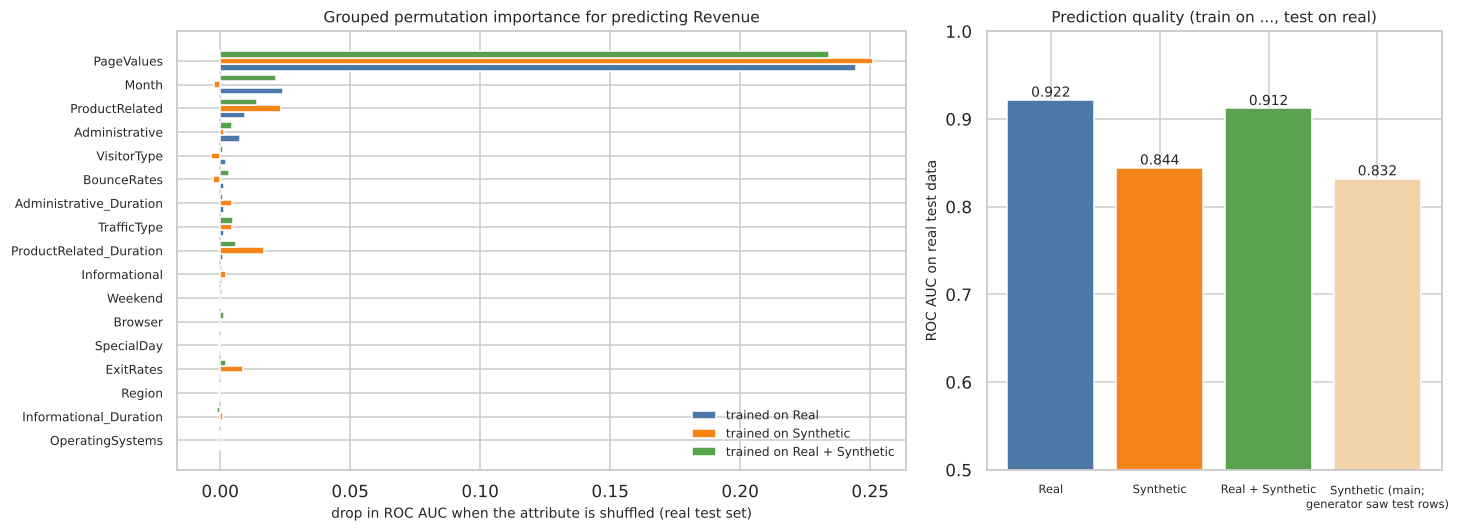

In [11]:
A.fig_importance(imp, perf, FIG / "a04_feature_importance.png")

**Interpretation.** PageValues is by far the most important attribute for predicting a purchase in all models: shuffling it lowers the test AUC by 0.24 (real model), 0.25 (model trained on synthetic data) and 0.23 (trained on both). All other attributes lower the AUC by 0.03 or less. The next largest in the real model is Month (0.024), which the synthetic model cannot use (-0.003), because the monthly conversion pattern is lost in the synthetic data; ProductRelated is more important in the synthetic model (0.023 against 0.010). Beyond PageValues the importances are small and partly noise, and the rank correlation between the real and the synthetic model is 0.16 (0.83 between the real model and the model trained on both). **Prediction quality on real test data:** the model trained on real rows reaches AUC 0.922 and average precision 0.72 (the purchase share is 0.16). The model trained on synthetic rows from a generator that never saw the test rows reaches 0.844 and 0.61, a loss of 0.077 AUC (paired bootstrap 95% interval 0.063 to 0.092), although it has 43% more rows. The main synthetic dataset, whose generator saw the test rows, reaches 0.832, so the exposure to the test rows did not make the synthetic model look better here (the 0.012 difference between the two synthetic datasets shows how much one generated sample can differ from another). Adding the refitted synthetic rows to the real training rows does not help: AUC 0.912, which is 0.0095 below the real-only model (paired bootstrap interval 0.006 to 0.013, outside the sampling noise of the test set; variation between splits is examined in 4.1).

### 4.1 Robustness: five different splits
The split, the generator refit and the models are repeated for five different seeds (42 to 46), and the test AUC is reported. This shows how much the AUC results depend on one particular split; the importance values are from the first split only.

In [12]:
rep = A.repeated_split_auc(real); rep["gap Real - Synthetic"] = rep["Real"] - rep["Synthetic"]; rep["gap Real - (Real + Synthetic)"] = rep["Real"] - rep["Real + Synthetic"]
rep.round(3).to_csv(RES / "importance_repeated_splits_auc.csv"); display(rep.round(3)); display(rep.agg(["mean", "std"]).round(3))

,Real,Synthetic,Real + Synthetic,gap Real - Synthetic,gap Real - (Real + Synthetic)
split seed,,,,,
42,0.922,0.844,0.912,0.077,0.010
43,0.927,0.866,0.918,0.061,0.009
44,0.925,0.850,0.912,0.076,0.013
45,0.930,0.861,0.921,0.069,0.010
46,0.929,0.858,0.920,0.070,0.009


,Real,Synthetic,Real + Synthetic,gap Real - Synthetic,gap Real - (Real + Synthetic)
mean,0.927,0.856,0.916,0.071,0.010
std,0.003,0.009,0.004,0.006,0.002


**Interpretation.** Over five different splits (each with its own generator refit) the test AUC is 0.927 on average (standard deviation 0.003) for the model trained on real rows, 0.856 (0.009) for the model trained on synthetic rows and 0.917 (0.004) for the model trained on both. The loss from training on synthetic data is 0.071 on average (range 0.061 to 0.077), and the small loss from adding synthetic rows to the real rows is 0.010 (0.009 to 0.013) in every split. The single-split results above are therefore typical, and the two conclusions do not depend on the particular split: training on synthetic data costs about 0.07 AUC, and adding it to real data does not help. Only the AUC was repeated; the importance values of the individual attributes come from the first split and are not stable enough to rank beyond PageValues.

### 4.2 Without PageValues
PageValues is the page-value metric of the website and dominates every model. The same analysis without it shows whether the remaining attributes carry any signal that the synthetic data reproduces.

In [13]:
perf2, imp2, boot2, _ = A.importance_analysis2(real, syn, drop=("PageValues",))
perf2.to_csv(RES / "importance_model_performance_without_pagevalues.csv"); imp2.to_csv(RES / "importance_permutation_without_pagevalues.csv"); boot2.round(4).to_csv(RES / "importance_auc_difference_bootstrap_without_pagevalues.csv")
display(perf2.round(3)); display(boot2.round(4)); display(imp2.sort_values("Real", ascending=False).round(4))
print("Spearman correlation of the importances between models:"); display(imp2.corr(method="spearman").round(2))

,ROC AUC,average precision,train rows
Real,0.773,0.389,8539.0
Synthetic (fitted on training rows only),0.684,0.269,12199.0
Real + Synthetic (fitted on training rows only),0.763,0.374,20738.0
Synthetic (main dataset; generator saw the test rows),0.673,0.264,12199.0
baseline: majority class,0.500,0.156,0.0


,difference,95% lower,95% upper
comparison,,,
AUC(Real) - AUC(Synthetic (fitted on training rows only)),0.0895,0.0707,0.1069
AUC(Real) - AUC(Real + Synthetic (fitted on training rows only)),0.0098,0.0036,0.0166
AUC(Real) - AUC(Synthetic (main dataset; generator saw the test rows)),0.0998,0.0821,0.1185


,Real,Synthetic (fitted on training rows only),Real + Synthetic (fitted on training rows only),Synthetic (main dataset; generator saw the test rows)
ProductRelated,0.0535,0.0871,0.0680,0.0460
Month,0.0367,0.0033,0.0293,-0.0048
ProductRelated_Duration,0.0299,0.0462,0.0367,0.0327
Administrative,0.0254,0.0122,0.0224,0.0067
ExitRates,0.0232,0.0605,0.0334,0.0459
VisitorType,0.0192,-0.0013,0.0114,0.0138
TrafficType,0.0072,0.0093,0.0099,0.0029
BounceRates,0.0061,0.0138,0.0123,-0.0068
Administrative_Duration,0.0058,0.0031,0.0067,-0.0015
Informational,0.0056,0.0017,0.0040,0.0090


Spearman correlation of the importances between models:


,Real,Synthetic (fitted on training rows only),Real + Synthetic (fitted on training rows only),Synthetic (main dataset; generator saw the test rows)
Real,1.00,0.66,0.91,0.44
Synthetic (fitted on training rows only),0.66,1.00,0.77,0.30
Real + Synthetic (fitted on training rows only),0.91,0.77,1.00,0.36
Synthetic (main dataset; generator saw the test rows),0.44,0.30,0.36,1.00


**Interpretation.** Without PageValues all models are much weaker (AUC 0.773 trained on real data, 0.684 on synthetic data and 0.763 on both; average precision 0.39, 0.27 and 0.37). The loss from training on synthetic data is 0.090 (paired bootstrap interval 0.071 to 0.107) and the loss from adding synthetic rows to real rows 0.010 (0.004 to 0.017). The attributes that carry the remaining signal in the real data are ProductRelated (0.054), Month (0.037), ProductRelated_Duration (0.030), Administrative (0.025), ExitRates (0.023) and VisitorType (0.019). The synthetic model relies on ProductRelated (0.087), ExitRates (0.061) and ProductRelated_Duration (0.046) more strongly than the real model does, and cannot use Month (0.003) or VisitorType (-0.001). The rank correlation of the importances between the real and the synthetic model is 0.66. So the synthetic data reproduces the main driver (PageValues) and, in exaggerated form, the browsing-volume signal, but loses the seasonal and visitor-type signals; the gain over chance (AUC above 0.5) is 0.27 for the real model against 0.18 for the synthetic one.

## 5. Task 4: Clustering
K-Means (10 starts, seed 42) on the same log-transformed and standardised ten base columns. The number of clusters is chosen by the silhouette score on the real data (the synthetic curve is shown for comparison). The cluster structures are compared in two ways: (a) each dataset is clustered on its own and the clusters of the synthetic fit are matched to the real ones by centroid distance (Hungarian algorithm); (b) the real clustering is applied to the synthetic rows (what share of synthetic rows falls into each real cluster). The purchase rate per cluster shows whether the clusters mean the same thing in both datasets.

In [14]:
sil = A.silhouette_curve(real, syn); sil.to_csv(RES / "silhouette_by_k.csv", index=False)
display(sil.pivot(index="k", columns="dataset", values="silhouette").round(3))
K = int(sil[sil.dataset == "Real"].sort_values("silhouette").k.iloc[-1]); print("k chosen on the real data:", K)

dataset,Real,Synthetic
k,,
2,0.266,0.220
3,0.358,0.220
4,0.320,0.228
5,0.345,0.242
6,0.351,0.249
7,0.318,0.243
8,0.312,0.225


k chosen on the real data: 3


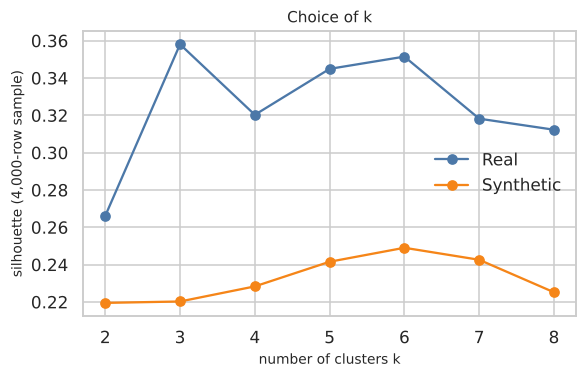

In [15]:
A.fig_silhouette(sil, FIG / "a05_silhouette.png")

**Interpretation.** The silhouette score of the real data peaks at k = 3 (0.358), with k = 6 (0.351) and k = 5 (0.345) close behind; the differences between these values are within what a 4,000-row sample can produce, so k = 3 is the maximum by convention and not a sharp optimum. The k = 3 peak is helped by the small, well-separated bounce group. The synthetic data has a weaker cluster structure at every k (silhouette 0.22 to 0.25, highest 0.249 at k = 6): its points form a more continuous cloud, in line with the more diffuse PCA picture. A silhouette of 0.36 is conventionally a weak to moderate structure, so the clusters are best read as a rough segmentation and not as sharply separated groups.

In [16]:
cl = A.cluster_analysis(real, syn, K)
cl["sizes"].round(1).to_csv(RES / "cluster_sizes.csv"); cl["purchase"].round(1).to_csv(RES / "cluster_purchase_rate.csv")
cl["profile_real"].round(2).to_csv(RES / "cluster_profile_real_means.csv"); cl["profile_syn"].round(2).to_csv(RES / "cluster_profile_synthetic_means.csv")
print("centroid distance of matched clusters (standardised units):", cl["centroid_dist"].round(2).to_dict())
print("adjusted Rand index, synthetic own fit vs real fit applied to synthetic:", round(cl["ari_applied_vs_own"], 3))
display(cl["sizes"].round(1)); display(cl["purchase"].round(1))
display(cl["profile_real"].round(2)); display(cl["profile_syn"].round(2))

centroid distance of matched clusters (standardised units): {'cluster 0': 1.38, 'cluster 1': 4.72, 'cluster 2': 0.74}
adjusted Rand index, synthetic own fit vs real fit applied to synthetic: 0.418


,Real (own fit),"Synthetic (own fit, matched)",Synthetic (real fit applied)
0,73.7,33.8,69.6
1,7.4,40.8,4.0
2,18.9,25.4,26.5


,Real (own fit),"Synthetic (own fit, matched)",Synthetic (real fit applied)
cluster,,,
0,14.9,15.5,13.6
1,0.4,11.8,7.5
2,24.5,16.3,16.8


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
cluster,,,,,,,,,,
0,1.85,62.16,0.04,0.26,26.15,961.00,0.01,0.03,5.86,0.06
1,0.04,0.33,0.02,0.08,2.76,42.51,0.16,0.18,0.00,0.11
2,5.15,178.00,2.53,172.31,63.97,2494.71,0.01,0.02,8.62,0.04


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
cluster,,,,,,,,,,
0,3.69,106.36,0.18,0.00,37.71,1393.42,0.01,0.03,7.20,0.05
1,0.22,2.07,0.14,1.23,15.79,648.91,0.02,0.06,3.40,0.07
2,3.22,96.42,2.07,85.52,54.07,2065.63,0.01,0.03,7.58,0.06


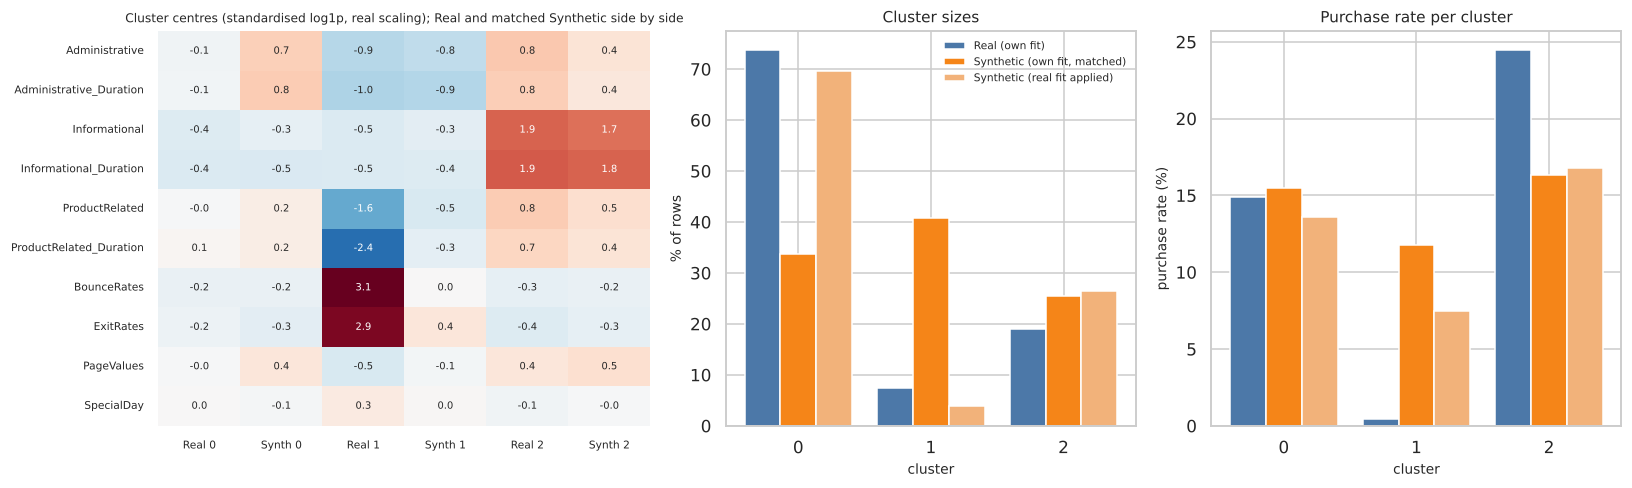

In [17]:
A.fig_clusters(cl, FIG / "a06_clusters.png")

**Interpretation.** In the real data the three clusters are (0) typical browsing sessions, 73.7% of the rows, with about 26 product pages and a purchase rate of 14.9%; (1) bounce sessions, 7.4%, with almost no pages, bounce and exit rates of 0.16 and 0.18, PageValues of 0 and a purchase rate of only 0.4%; and (2) intensive sessions, 18.9%, with about 64 product pages, 2.5 informational pages and the highest purchase rate, 24.5%. The synthetic data does not reproduce this structure. Clustered on its own, it gives groups of 34%, 41% and 25% of the rows; matched to the real clusters by centroid distance, the matched cluster 1 is not a bounce group (it has 15.8 product pages and a bounce rate of 0.02), and its purchase rate is 11.8%. Applying the *real* clustering to the synthetic rows gives 69.6%, 4.0% and 26.5%: the shares of the browsing and intensive clusters are in the right range (differences of 4 and 8 percentage points), but the bounce cluster has only about half its real size and a purchase rate of 7.5% instead of 0.4%. The distance between matched cluster centres is 1.4 (cluster 0), 4.7 (cluster 1) and 0.7 (cluster 2) in standardised units, so the bounce cluster is the one that differs most. The purchase rate of the intensive cluster is 24.5% in the real data and about 16% to 17% in the synthetic data, which repeats the weakened purchase signal found in Phase 6. The adjusted Rand index between the synthetic own clustering and the real clustering applied to the synthetic rows is only 0.42.

### 5.1 Sensitivity to the number of clusters
The same comparison for other values of k, to show how much the conclusion depends on the choice of k.

In [18]:
rows = []
for k in (2, 3, 4, 5, 6):
    r = A.cluster_analysis(real, syn, k)
    rows.append({"k": k, "mean centroid distance": r["centroid_dist"].mean(), "max |share gap| real vs synthetic fit applied (pp)": (r["sizes"]["Real (own fit)"] - r["sizes"]["Synthetic (real fit applied)"]).abs().max(),
                 "max |share gap| real vs synthetic own fit (pp)": (r["sizes"]["Real (own fit)"] - r["sizes"]["Synthetic (own fit, matched)"]).abs().max(),
                 "ARI own fit vs applied": r["ari_applied_vs_own"]})
sens = pd.DataFrame(rows).set_index("k"); sens.round(3).to_csv(RES / "cluster_sensitivity_k.csv"); sens.round(3)

,mean centroid distance,max |share gap| real vs synthetic fit applied (pp),max |share gap| real vs synthetic own fit (pp),ARI own fit vs applied
k,,,,
2,1.602,3.689,21.223,0.139
3,2.278,7.550,39.954,0.418
4,2.033,6.009,5.943,0.772
5,1.980,5.410,12.001,0.652
6,1.747,5.418,5.435,0.529


**Interpretation.** How well the cluster structures agree depends strongly on k. For k = 4 the synthetic own clustering is closest to the real clustering applied to it (adjusted Rand index 0.77) and the cluster sizes agree within about 6 percentage points; for k = 5 and k = 6 the largest size gap is about 5 to 12 points. For k = 2 and k = 3 the agreement is poor (ARI 0.14 and 0.42; largest size gap of the own fit 21 and 40 points). The value k = 3 chosen on the real data is therefore a case where the structures differ clearly, and a different choice of k would have given a more favourable picture on these two measures. The measures have limits: the adjusted Rand index compares two clusterings of the *synthetic* rows (its own fit and the real fit applied to it), not the real and the synthetic structure directly, and cluster sizes say nothing about cluster contents. At k = 4, where the sizes agree best, the matched cluster centres of the three larger clusters are close (distances 0.3 to 0.8 in standardised units), but the real bounce cluster (6.5% of the real rows) is far from its synthetic counterpart (distance 6.4), and the real clustering puts only 2.7% of the synthetic rows into it against 7.6% in the synthetic own fit. The conclusion is therefore limited: the sizes of the larger clusters can be matched at finer k, but the small bounce group with its near-zero purchase rate is not reproduced at any k examined. Purchase rates per cluster were not compared for k other than 3.

## 6. Summary of the four tasks

In [19]:
summary = pd.DataFrame([
    ["1. Hypothesis tests", f"{int(nt['significant (Holm, 5%)'].sum())} of 14 numerical columns differ significantly (Mann-Whitney, Holm); {int(nt['non-negligible'].sum())} are non-negligible. {int(ct['significant (Holm, 5%)'].sum())} of 10 categorical columns differ significantly (Revenue only); none has Cramér's V of 0.1."],
    ["2. PCA", f"Same overall layout; PC1 explains {100*pca['var'].iloc[0,1]:.0f}% of the real and {100*pca['var'].iloc[0,2]:.0f}% of the synthetic variance; loading similarity {pca['var']['loading cosine similarity'].min():.2f} to {pca['var']['loading cosine similarity'].max():.2f}. A classifier separates the datasets with AUC {clf2.iloc[0]:.2f}."],
    ["3. Feature importance", f"PageValues is first in every model. Predicting real purchases: AUC {perf.loc['Real','ROC AUC']:.3f} (trained on real), {perf.loc['Synthetic (fitted on training rows only)','ROC AUC']:.3f} (trained on synthetic), {perf.loc['Real + Synthetic (fitted on training rows only)','ROC AUC']:.3f} (both)."],
    ["4. Clustering", f"k = {K} chosen on the real data (silhouette {sil[(sil.dataset=='Real')&(sil.k==K)].silhouette.iloc[0]:.2f} real, {sil[(sil.dataset=='Synthetic')&(sil.k==K)].silhouette.iloc[0]:.2f} synthetic); cluster sizes and purchase rates differ (see 5)."],
], columns=["Task", "Main result"]).set_index("Task")
summary.to_csv(RES / "advanced_summary.csv"); summary

,Main result
Task,
1. Hypothesis tests,6 of 14 numerical columns differ significantly...
2. PCA,Same overall layout; PC1 explains 43% of the r...
3. Feature importance,PageValues is first in every model. Predicting...
4. Clustering,k = 3 chosen on the real data (silhouette 0.36...


**Interpretation.** The four tasks give a consistent picture. One-column tests find the two datasets close (small effect sizes, 1 of 10 categorical columns different, 6 of 14 numerical columns significantly different but only 3 beyond a small effect). Tasks that use several columns at once find larger differences: a classifier recognises synthetic rows with AUC 0.95 (0.82 from the column distributions alone), the cluster structure differs, and models trained on synthetic data predict purchases clearly worse on real data (AUC 0.84 against 0.92, with a generator that never saw the test rows). What the synthetic data does keep is the large-scale layout (PCA arch, first component, overall activity) and the dominant predictor (PageValues).

## 7. Written conclusions on statistical significance and practical importance

**Statistical significance is not practical importance, and the single-column tests are not the whole picture.** (1) With 12,199 rows per dataset, small differences are detected (6 numerical columns after Holm correction, Revenue among the categorical columns), but their effect sizes are small (largest |d| 0.18, largest |rank-biserial| 0.11, largest Cramér's V 0.024). (2) A non-significant result is not evidence of equality: the absence of a significant difference in a column (for example Month, p = 0.59) says only that a difference of that size could not be detected, and no equivalence test was run. (3) Many small differences add up. A classifier that sees all columns separates the datasets with AUC 0.95; it still reaches 0.82 when all relationships between columns are destroyed, so most of the separability comes from the column distributions, and the joint structure adds about 0.12 (0.81 on the categorical columns alone, where the one-way proportions match). (4) For use, the question is what the data is used for. For the overall layout, the main predictor (PageValues) and the one-way proportions it is close enough. For training a purchase model it costs about 0.07 to 0.08 AUC on real test data (0.844 against 0.922 on one split, 0.071 on average over five splits, about 0.09 without PageValues), and adding it to real data brings no gain (a loss of about 0.01). For finding small groups (the bounce sessions), seasonal conversion or associations between categories it is not suitable. (5) **Limits of this notebook.** The synthetic rows were generated from the real rows, so the two samples are not independent, and the p-values describe how detectable a difference is, not inference about two populations. The prediction experiment refits the generator on the training rows to avoid any exposure to the test rows, which makes its synthetic data a second generated sample (its AUC differs by about 0.01 from that of the main synthetic dataset). The AUC was repeated over five splits, but the attribute importances and the clustering use one split and one seed, and k was examined only from 2 to 6. The Combined dataset was not analysed separately, because the brief asks for the real and the synthetic data.

## 8. Outputs
Figures: `figures/advanced/`; tables: `results/advanced/`.